# Capstone C3 starter · SO-101 in simulation: kinematics, workspace, joint-space demos, and the path to the real arm

In [1]:
import os, numpy as np, mujoco, mujoco_menagerie as mm, matplotlib.pyplot as plt
from vlacourse import show_video, show_images

def so101(cube_xy=(0.25, 0.0), half=0.012):
    spec = mm.get("robotstudio_so101").spec("scene")
    b = spec.worldbody.add_body(name="cube", pos=[*cube_xy, half]); b.add_freejoint()
    b.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[half] * 3, rgba=[0.9, 0.2, 0.2, 1], mass=0.01)
    m = spec.compile(); d = mujoco.MjData(m); mujoco.mj_forward(m, d)
    return m, d

def ik_down(m, d, target, q0, w=0.5, iters=300, n=5):
    """5-DoF: exact position + soft 'jaw points down' (the jaw axis is the gripperframe site's x axis)."""
    sid, q = m.site("gripperframe").id, q0.copy()
    jp, jr = np.zeros((3, m.nv)), np.zeros((3, m.nv))
    for _ in range(iters):
        d.qpos[:n] = q; mujoco.mj_kinematics(m, d); mujoco.mj_comPos(m, d)
        a = d.site_xmat[sid].reshape(3, 3)[:, 0]
        e = np.r_[target - d.site_xpos[sid], w * np.cross(a, [0, 0, -1])]
        mujoco.mj_jacSite(m, d, jp, jr, sid); J = np.vstack([jp[:, :n], w * jr[:, :n]])
        q = np.clip(q + J.T @ np.linalg.solve(J @ J.T + 1e-3 * np.eye(6), e), m.jnt_range[:n, 0], m.jnt_range[:n, 1])
    return q, float(np.linalg.norm(target - d.site_xpos[sid]))

joints: ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper'] | actuators: ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']


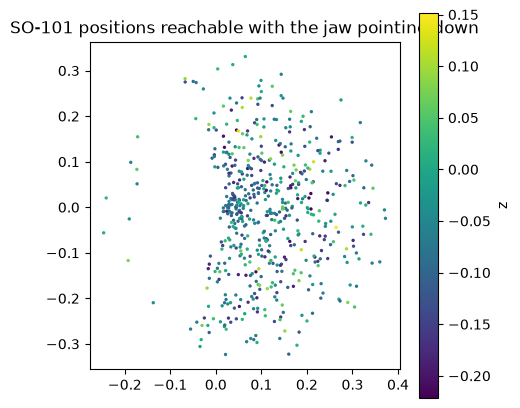

In [2]:
m, d = so101()
print("joints:", [m.joint(i).name for i in range(6)], "| actuators:", [m.actuator(i).name for i in range(m.nu)])
rng = np.random.default_rng(0); pts = []
for _ in range(4000):
    d.qpos[:5] = rng.uniform(m.jnt_range[:5, 0], m.jnt_range[:5, 1]); mujoco.mj_kinematics(m, d)
    if d.site_xmat[m.site("gripperframe").id].reshape(3, 3)[2, 0] < -0.9:
        pts.append(d.site_xpos[m.site("gripperframe").id].copy())
pts = np.array(pts)
plt.figure(figsize=(5, 5)); plt.scatter(pts[:, 0], pts[:, 1], s=2, c=pts[:, 2]); plt.gca().set_aspect("equal"); plt.colorbar(label="z")
plt.title("SO-101 positions reachable with the jaw pointing down"); plt.show()

In [3]:
m, d = so101(); q = np.zeros(5); frames = []; cube = d.body("cube").xpos.copy()
traj = []
with mujoco.Renderer(m, 240, 320) as r:
    for tgt, jaw in [(cube + [0, 0, 0.06], 1.0), (cube + [0, 0, 0.005], 1.0), (cube + [0, 0, 0.06], 1.0), (np.array([0.18, 0.15, 0.06]), 1.0)]:
        qg, err = ik_down(m, d, tgt, q)
        for i in range(250):
            s = min(1, (i + 1) / 200); d.ctrl[:5] = q + (qg - q) * (3 * s * s - 2 * s ** 3); d.ctrl[5] = jaw
            mujoco.mj_step(m, d); traj.append(np.r_[d.ctrl[:6]].copy())
            if i % 20 == 0:
                cam = mujoco.MjvCamera(); cam.lookat[:] = [0.2, 0.05, 0.05]; cam.distance, cam.azimuth, cam.elevation = 0.7, 120, -25
                r.update_scene(d, cam); frames.append(r.render())
        q = qg
show_video(frames, fps=20, title="SO-101 reach")
np.save("so101_joint_demo.npy", np.array(traj))
print("saved a joint-space trajectory (6-D: 5 joints + jaw), the same format lerobot-record stores for a real SO-101")

saved a joint-space trajectory (6-D: 5 joints + jaw), the same format lerobot-record stores for a real SO-101


In [4]:
print("""Your capstone:
 1. Make the grasp work in sim: tune the pre-grasp offset so the cube sits between the fixed and moving jaw; sweep jaw opening.
 2. Script 100 randomized pick-and-place demos; store them as a LeRobotDataset v3 (S12 notebook 117) with 6-D joint actions.
 3. Train ACT or SmolVLA on them (S08 / S13 notebook 127), evaluate in sim with Wilson intervals (S12).
 4. Real arm (optional): lerobot-calibrate / lerobot-teleoperate a leader+follower SO-101, lerobot-record 50 real episodes,
    fine-tune your sim policy on them (S13), and compare sim-only vs sim+real on 20 real trials.""")

Your capstone:
 1. Make the grasp work in sim: tune the pre-grasp offset so the cube sits between the fixed and moving jaw; sweep jaw opening.
 2. Script 100 randomized pick-and-place demos; store them as a LeRobotDataset v3 (S12 notebook 117) with 6-D joint actions.
 3. Train ACT or SmolVLA on them (S08 / S13 notebook 127), evaluate in sim with Wilson intervals (S12).
 4. Real arm (optional): lerobot-calibrate / lerobot-teleoperate a leader+follower SO-101, lerobot-record 50 real episodes,
    fine-tune your sim policy on them (S13), and compare sim-only vs sim+real on 20 real trials.
